In [1]:
import pandas as pd
import pandas as pd, numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("../Datasets/unsw_train.csv")
df_t=pd.read_csv("../Datasets/unsw_test.csv")

In [6]:
SEUIL_CONST = 0.97
SEUIL_CORR = 0.9

feat_cols = [c for c in df.columns if c not in ["id", "attack_cat", "label"]]
df_dedup = df.drop_duplicates(subset=feat_cols).reset_index(drop=True)

def select_features(data, seuil_const=SEUIL_CONST,
                    seuil_corr=SEUIL_CORR, verbose=True):
    y = data["label"]
    X = data.drop(columns=["id", "attack_cat", "label"])

    # 1. Colonnes quasi constantes (sauf celles protégées)
    quasi_const = [c for c in X.columns
                   if X[c].value_counts(normalize=True).iloc[0] > seuil_const]
    X = X.drop(columns=quasi_const)

    # 2. Information mutuelle de chaque feature numérique avec le label
    num = X.select_dtypes("number")
    mi = pd.Series(mutual_info_classif(num, y, random_state=42), index=num.columns)

    # 3. Paires corrélées, de la plus forte à la plus faible
    corr = num.corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    pairs = upper.stack().loc[lambda s: s > seuil_corr].sort_values(ascending=False)

    # 4. Pour chaque paire, on supprime la moins informative (jamais une colonne protégée)
    dropped = set()
    for (a, b), r in pairs.items():
        if a in dropped or b in dropped:
            continue
        else:
            loser = a if mi[a] < mi[b] else b
        dropped.add(loser)
        if verbose:
            print(f"{a} vs {b} (r={r:.2f}) -> on supprime {loser}")

    feats = [c for c in X.columns if c not in dropped]
    if verbose:
        print("Quasi constantes :", quasi_const)
        print("Features restantes :", len(feats))
    return feats

val  avec copie dans train : 0
test avec copie dans train : 0
dbytes vs dloss (r=1.00) -> on supprime dloss
sbytes vs sloss (r=1.00) -> on supprime sloss
dpkts vs dbytes (r=0.98) -> on supprime dpkts
spkts vs sbytes (r=0.96) -> on supprime spkts
swin vs dwin (r=0.95) -> on supprime swin
tcprtt vs synack (r=0.94) -> on supprime synack
ct_srv_src vs ct_srv_dst (r=0.92) -> on supprime ct_srv_src
Quasi constantes : ['is_ftp_login', 'ct_ftp_cmd', 'is_sm_ips_ports']
Features restantes : 32
Features retenues : 32
['dur', 'proto', 'service', 'state', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst']

                    Accuracy  Precision  Recall      F1  ROC-AUC
Majoritaire (val)    0.6340     0.0000  0.0000  0.0

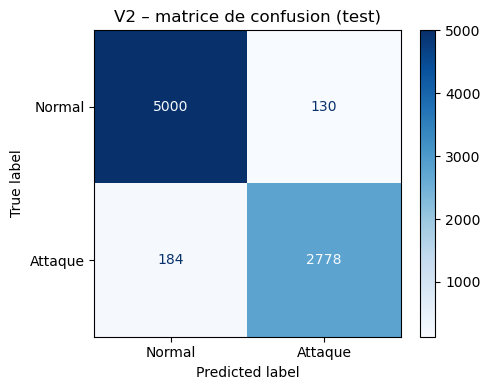

num__ct_dst_src_ltm    0.1361
num__sttl              0.0897
num__ct_srv_dst        0.0813
num__ct_state_ttl      0.0597
num__dload             0.0464
num__sbytes            0.0457
num__tcprtt            0.0433
num__smean             0.0424
num__dbytes            0.0347
num__rate              0.0330
dtype: float64


In [7]:
# 1. Split sur les données dédoublonnées (70 / 15 / 15)
train_df, temp_df = train_test_split(df_dedup, test_size=0.30, stratify=df_dedup["label"], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=42)


# 2. Sélection des features sur le TRAIN uniquement
features = select_features(train_df)
print("Features retenues :", len(features))
print(features)

cat_cols = [c for c in ["proto", "service", "state"] if c in features]
num_cols = [c for c in features if c not in cat_cols]
X_train, y_train = train_df[features], train_df["label"]
X_val,   y_val   = val_df[features],   val_df["label"]
X_test,  y_test  = test_df[features],  test_df["label"]

# 3. Modèles
prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=0.01), cat_cols),
    ("num", "passthrough", num_cols),
])
dummy = Pipeline([("prep", prep), ("model", DummyClassifier(strategy="most_frequent"))])
rf = Pipeline([("prep", prep),
               ("model", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))])
dummy.fit(X_train, y_train)
rf.fit(X_train, y_train)

# 4. Évaluation
def evaluate(model, X_, y_):
    pred = model.predict(X_)
    proba = model.predict_proba(X_)[:, 1]
    return {"Accuracy": accuracy_score(y_, pred),
            "Precision": precision_score(y_, pred, zero_division=0),
            "Recall": recall_score(y_, pred),
            "F1": f1_score(y_, pred),
            "ROC-AUC": roc_auc_score(y_, proba)}

results = pd.DataFrame({
    "Majoritaire (val)": evaluate(dummy, X_val, y_val),
    "RF train": evaluate(rf, X_train, y_train),
    "RF validation": evaluate(rf, X_val, y_val),
    "RF test": evaluate(rf, X_test, y_test),
}).T.round(4)
print("\n", results)

for name, X_, y_ in [("validation", X_val, y_val), ("test", X_test, y_test)]:
    tn, fp, fn, tp = confusion_matrix(y_, rf.predict(X_)).ravel()
    print(f"{name}: VN={tn}  FP={fp}  FN={fn}  VP={tp}")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test,
                                      display_labels=["Normal", "Attaque"], cmap="Blues", ax=ax)
ax.set_title("V2 – matrice de confusion (test)")
plt.tight_layout(); plt.show()

names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)
print(imp.head(10).round(4))